In [67]:
# Optional: install dmba if not already installed
!pip install dmba

# Data manipulation
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from IPython.display import YouTubeVideo, display, HTML

# Machine learning models
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor, GradientBoostingClassifier

# Preprocessing and pipelines
from sklearn.preprocessing import StandardScaler, MinMaxScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Model selection and evaluation
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error, classification_report, roc_auc_score

# DMBA helper functions
from dmba import plotDecisionTree, classificationSummary, regressionSummary





In [68]:
#Establishing a path to Drive to connect the dataset
from google.colab import drive
my_drive_path = "/content/drive/MyDrive/"

In [69]:
#Connecting the dataset to my drive path and establishing a dataframe
data = pd.read_csv(my_drive_path + "youtube.csv")
df = pd.DataFrame(data)
df.head() #Printing the first five columns

,category_id,views,likes,dislikes,comment_count,comments_disabled,ratings_disabled,video_error_or_removed
0,22,748374.0,57527.0,2966,15954.0,0,0,0
1,24,2418783.0,97185.0,6146,12703.0,0,0,0
2,23,681944.0,146033.0,5339,8181.0,0,0,0
3,24,343168.0,10172.0,666,2146.0,0,0,0
4,24,2095731.0,132235.0,1989,17518.0,0,0,0


In [70]:
#Data Preparation
df.info()
df.head()
df.shape

#convert all floats to integers
df['views'] = df['views'].astype(int)
df['likes'] = df['likes'].astype(int)
df['comment_count'] = df['comment_count'].astype(int)

y = np.log1p(df['views'])



<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40949 entries, 0 to 40948
Data columns (total 8 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   category_id             40949 non-null  int64  
 1   views                   40949 non-null  float64
 2   likes                   40949 non-null  float64
 3   dislikes                40949 non-null  int64  
 4   comment_count           40949 non-null  float64
 5   comments_disabled       40949 non-null  int64  
 6   ratings_disabled        40949 non-null  int64  
 7   video_error_or_removed  40949 non-null  int64  
dtypes: float64(3), int64(5)
memory usage: 2.5 MB


In [71]:
numeric_transformer = Pipeline(steps=[
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)


In [72]:
target = 'views'
X = df.drop(columns=['views'])
y = df['views']

X = df.drop(columns=[target])
y = df[target]

# Separate numeric & categorical features
numeric_features = X.select_dtypes(include=['int64', 'float64']).columns
categorical_features = X.select_dtypes(include=['object', 'category']).columns

#1. Choose Observations and Features:

Select a subset of observations (minimum of 1,000).
You may select a subset of features based on your chosen modeling approach.


In [73]:
valid_cols = df.columns[df.notna().sum() >= 1000]
valid_cols


#Regression
reg_target = "views"
reg_features = [c for c in valid_cols if c != reg_target]

df_reg = df[[reg_target] + reg_features].dropna()

#Classification
class_target = "comments_disabled"
class_features = [c for c in valid_cols if c != class_target]

df_class = df[[class_target] + class_features].dropna()



#Choosing views and comments disabled as subset of observations because they both have >1000.


# 2. Model Implementation:
Implement at least two different models from the techniques covered so far:

Multiple Linear Regression

Classification and Regression Trees



              precision    recall  f1-score   support

           0       1.00      1.00      1.00      8065
           1       0.89      0.96      0.92       125

    accuracy                           1.00      8190
   macro avg       0.94      0.98      0.96      8190
weighted avg       1.00      1.00      1.00      8190



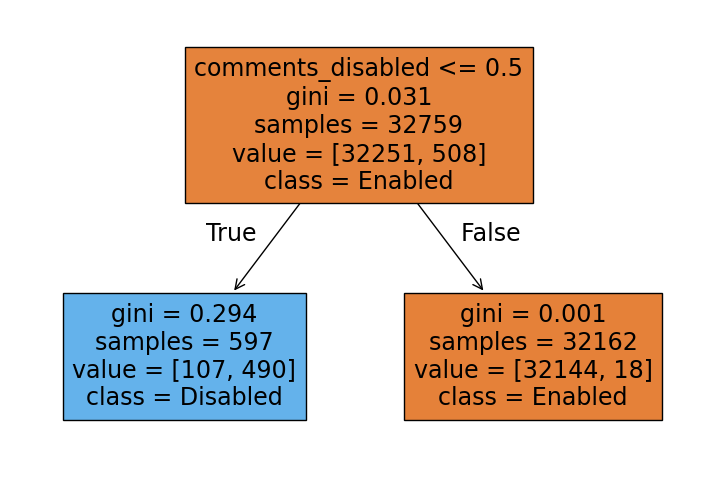

In [74]:
clf = DecisionTreeClassifier(random_state=0, max_depth=1)
clf.fit(X_train, y_train)

y_pred = clf.predict(X_test)
print(classification_report(y_test, y_pred))

plt.figure(figsize=(9, 6))
plot_tree(
    clf,
    feature_names=X.columns,
    class_names=["Enabled", "Disabled"],
    filled=True
)
plt.show()


R2 Score: 0.7485058070230755
MAE: 1328853.2938830024


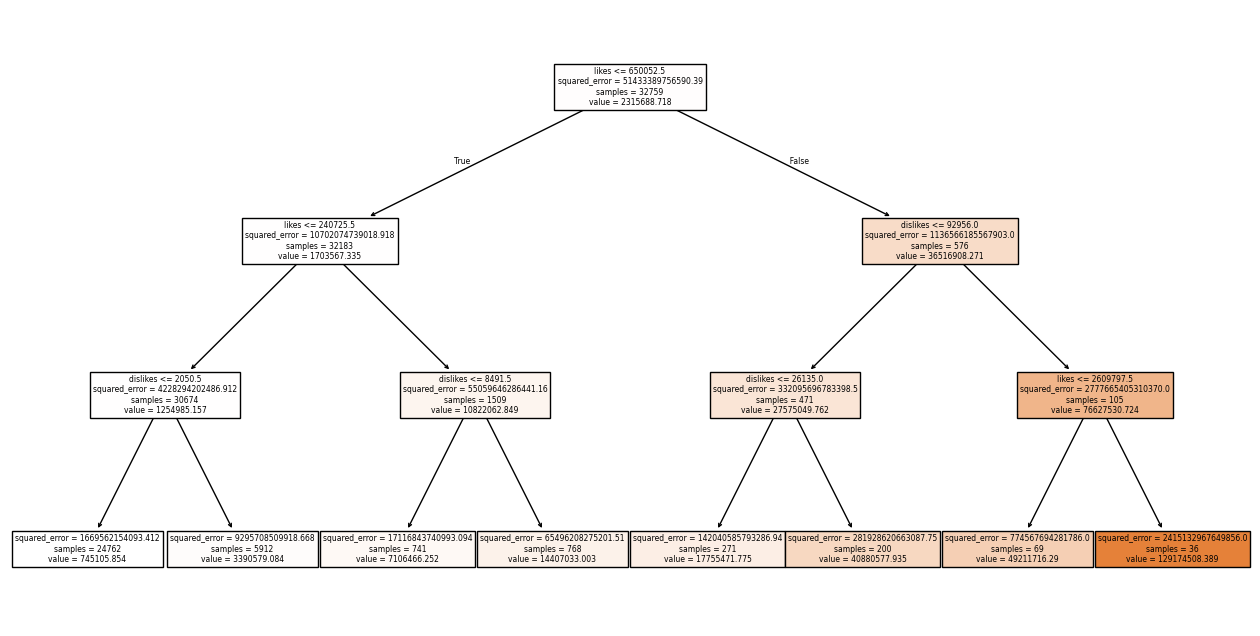

In [75]:
# Objective 2: Regression Task: Predict number of views


# Predict number of views using all other columns
X_reg = df.drop(columns="views")
y_reg = df["views"]

# Split the data
Xr_train, Xr_test, yr_train, yr_test = train_test_split(
    X_reg, y_reg, test_size=0.2, random_state=0
)

# Create and fit DecisionTreeRegressor
reg = DecisionTreeRegressor(random_state=0, max_depth=3)
reg.fit(Xr_train, yr_train)

# Evaluate
y_reg_pred = reg.predict(Xr_test)

print("R2 Score:", r2_score(yr_test, y_reg_pred))
print("MAE:", mean_absolute_error(yr_test, y_reg_pred))

# Plot the regression tree
plt.figure(figsize=(16, 8))
plot_tree(
    reg,
    feature_names=X_reg.columns,
    filled=True
)
plt.show()

#The regression tree is also a part of the CART method, along with classification, and it is helpful in determining the relationship between the features and the target, which may not be a linear relationship. Regression trees handle the non-linearity of the dataset well. They can also effectively predict continous outcomes, which is helpful for something like which comments will be disabled in the future videos, and this cannot be predicted by classfication.

Linear Regression R2: 0.4176216569342037
Linear Regression MAE: 1866625.2678071577
[ 2574161.16790303  2369660.57811252  2301577.36170782 ...
  1310776.79932938  4278587.53552264 20779049.1427057 ]
                  Feature   Coefficient
0             category_id -1.070733e+05
1                   likes  4.269671e+00
2                dislikes  3.089961e+01
3           comment_count  7.934218e+01
4       comments_disabled  1.117602e+06
5        ratings_disabled  2.037699e+06
6  video_error_or_removed -1.013311e+06


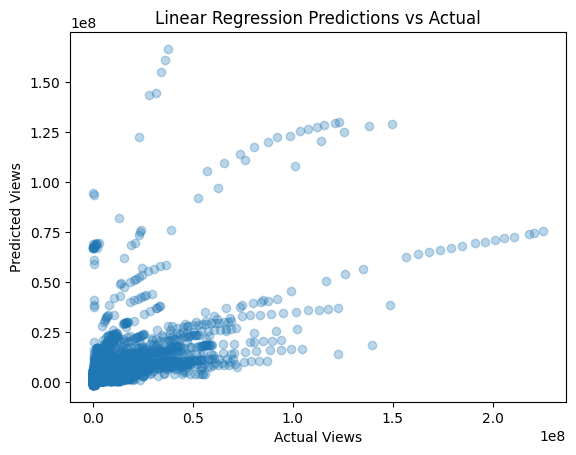

In [76]:
#Multiple Linear Regression:

# Train Linear Regression
lin_reg = LinearRegression()
lin_reg.fit(Xr_train, yr_train)

# Predict on test set
y_lr_pred = lin_reg.predict(Xr_test)

# Print evaluation metrics
print("Linear Regression R2:", r2_score(yr_test, y_lr_pred))
print("Linear Regression MAE:", mean_absolute_error(yr_test, y_lr_pred))

#Fit on full data for predictions
lin_reg.fit(X_reg, y_reg)
predictions = lin_reg.predict(X_reg)
print(predictions)


#Visualizing
coefficients = pd.DataFrame({
    'Feature': X_reg.columns,
    'Coefficient': lin_reg.coef_
})
print(coefficients)


#Plotting
plt.scatter(y_reg, predictions, alpha=0.3)
plt.xlabel("Actual Views")
plt.ylabel("Predicted Views")
plt.title("Linear Regression Predictions vs Actual")
plt.show()

#I chose the Multiple linear regression(MLR) as the second model because it is simple and easy to interpret. It can also provide an interpretation of the performance as well as comparison between models. Both multiple linear regression, and regression tree measures the R2 as well as the MAE metrics and the difference between the CART model and MLR is that MLR assumes a linear relationship.

In [77]:
#GridSearchCV for cross validation

cart = DecisionTreeRegressor(random_state=42)

cart_param_grid = {
    'max_depth': [None, 5, 10, 20],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 5]
}

cart_grid = GridSearchCV(
    estimator=cart,
    param_grid=cart_param_grid,
    cv=5,
    scoring='neg_root_mean_squared_error',
    n_jobs=-1,
    error_score='raise'
)

cart_grid.fit(X, y)

print("Best CART params:", cart_grid.best_params_)
print("Best CART RMSE:", -cart_grid.best_score_)


Best CART params: {'max_depth': 10, 'min_samples_leaf': 1, 'min_samples_split': 10}
Best CART RMSE: 3458826.615966259


In [78]:

ridge_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('model', Ridge())
])

ridge_param_grid = {
    'model__alpha': [0.01, 0.1, 1, 10, 100]
}

ridge_grid = GridSearchCV(
    estimator=ridge_pipeline,
    param_grid=ridge_param_grid,
    cv=5,
    scoring='neg_root_mean_squared_error',
    n_jobs=-1
)

ridge_grid.fit(X, y)

print("Best Ridge params:", ridge_grid.best_params_)
print("Best Ridge RMSE:", -ridge_grid.best_score_)



Best Ridge params: {'model__alpha': 100}
Best Ridge RMSE: 5783834.578643002


In [79]:
#Ridge regression
y_log = np.log1p(y)
ridge_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('ridge', Ridge())
])

ridge_param_grid = {
    'ridge__alpha': [0.01, 0.1, 1, 10, 100]
}

ridge_grid = GridSearchCV(
    estimator=ridge_pipeline,
    param_grid=ridge_param_grid,
    cv=5,
    scoring='neg_root_mean_squared_error',
    n_jobs=-1
)

ridge_grid.fit(X, y_log)  # or y

print("Best Ridge alpha:", ridge_grid.best_params_)
print("Best Ridge RMSE:", -ridge_grid.best_score_)


Best Ridge alpha: {'ridge__alpha': 100}
Best Ridge RMSE: 1.6806149775761097


In [80]:
#Lasso Regression
lasso_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('lasso', Lasso(max_iter=50000))
])

lasso_param_grid = {
    'lasso__alpha': [0.0001, 0.001, 0.01, 0.1, 1]
}

lasso_grid = GridSearchCV(
    estimator=lasso_pipeline,
    param_grid=lasso_param_grid,
    cv=5,
    scoring='neg_root_mean_squared_error',
    n_jobs=-1
)

lasso_grid.fit(X, y_log)  # or y

print("Best Lasso alpha:", lasso_grid.best_params_)
print("Best Lasso RMSE:", -lasso_grid.best_score_)





Best Lasso alpha: {'lasso__alpha': 0.1}
Best Lasso RMSE: 1.6590359570681237


#Comparison and Conclusion:

Compare model performance.

Write a brief conclusion on which model you would recommend and why.

Classification Tree Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      8065
           1       0.98      0.95      0.96       125

    accuracy                           1.00      8190
   macro avg       0.99      0.98      0.98      8190
weighted avg       1.00      1.00      1.00      8190

Regression Tree R2: 0.7485058070230755
Regression Tree MAE: 1328853.2938830024
Linear Regression R2: 0.4176216569342037
Linear Regression MAE: 1866625.2678071577


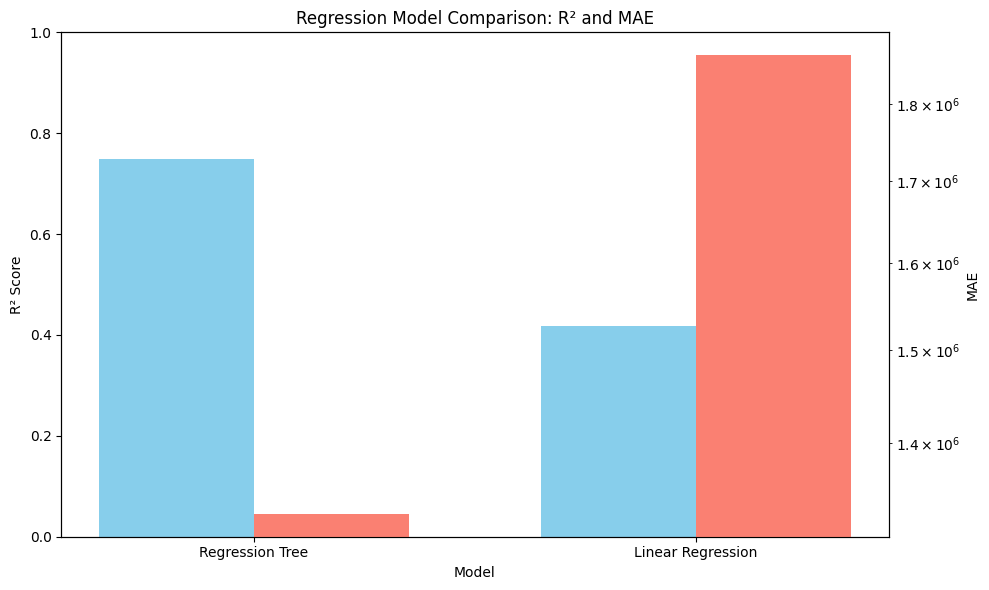

In [81]:
#Side by side comparison of models
import numpy as np
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, accuracy_score, classification_report

# Plotting Classification Tree
clf = DecisionTreeClassifier(random_state=0)
clf.fit(X_train, y_train)
y_clf_pred = clf.predict(X_test)
print("Classification Tree Report:")
print(classification_report(y_test, y_clf_pred))

# Plotting Regression Tree
reg = DecisionTreeRegressor(random_state=0, max_depth=3)
reg.fit(Xr_train, yr_train)
y_reg_pred = reg.predict(Xr_test)
reg_r2 = r2_score(yr_test, y_reg_pred)
reg_mae = mean_absolute_error(yr_test, y_reg_pred)
print("Regression Tree R2:", reg_r2)
print("Regression Tree MAE:", reg_mae)

# Plotting Linear Regression
lin_reg = LinearRegression()
lin_reg.fit(Xr_train, yr_train)
y_lr_pred = lin_reg.predict(Xr_test)
lr_r2 = r2_score(yr_test, y_lr_pred)
lr_mae = mean_absolute_error(yr_test, y_lr_pred)
print("Linear Regression R2:", lr_r2)
print("Linear Regression MAE:", lr_mae)

# Plotting Bar Chart for Regression Models
models = ["Regression Tree", "Linear Regression"]
r2_scores = [reg_r2, lr_r2]
mae_values = [reg_mae, lr_mae]

x = np.arange(len(models))
width = 0.35

fig, ax1 = plt.subplots(figsize=(10,6))

# R² bars
bars1 = ax1.bar(x - width/2, r2_scores, width, color='skyblue', label='R² Score')
ax1.set_ylabel('R² Score')
ax1.set_ylim(0, 1)
ax1.set_xticks(x)
ax1.set_xticklabels(models)
ax1.set_xlabel('Model')
ax1.set_title('Regression Model Comparison: R² and MAE')

# MAE bars on secondary axis
ax2 = ax1.twinx()
bars2 = ax2.bar(x + width/2, mae_values, width, color='salmon', label='MAE')
ax2.set_ylabel('MAE')
ax2.set_yscale('log')

# Combine legends
bars = bars1 + bars2
labels = [b.get_label() for b in bars]


plt.tight_layout()
plt.show()


#The orange bars show the MAE scores, whereas the blue bars show the the R2 scores. According to the comparison chart below, the classification and regression model shows the highest R2 and lowest MAE scores, which indicates the most accurate prediction of the model, and this is better than the MLR model, which may occur because the relationships between the feature and target is not linear.


In [82]:
results = pd.DataFrame({
    'Model': ['Ridge', 'Lasso'],
    'RMSE': [
        -ridge_grid.best_score_,
        -lasso_grid.best_score_
    ]
})

print(results)


   Model      RMSE
0  Ridge  1.680615
1  Lasso  1.659036


Title: Disabled cat is so happy to make a friend
Comments Disabled: No
R² Score: 0.9188
MAE: 0.00122


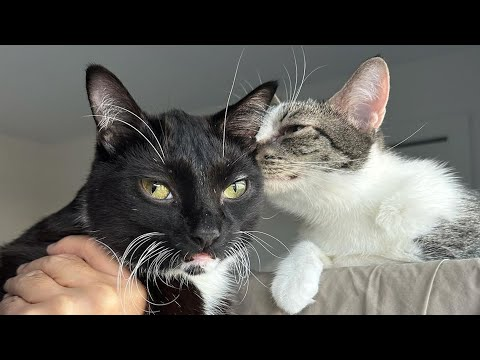

--------------------------------------------------
Title: YouTube Disabled Comments on My Videos - YouTube Banned Comments?
Comments Disabled: Yes
R² Score: 0.9269
MAE: 0.0011


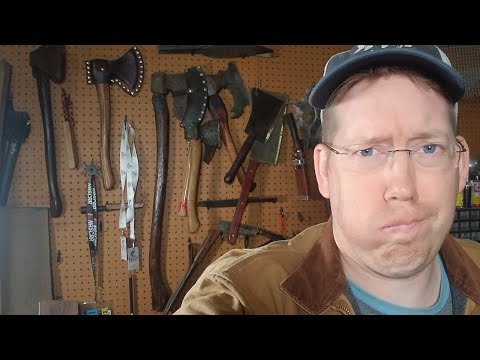

--------------------------------------------------
Title: Bob Ross - One Hour Special - The Grandeur of Summer
Comments Disabled: No
R² Score: 0.7622
MAE: 1866625.27


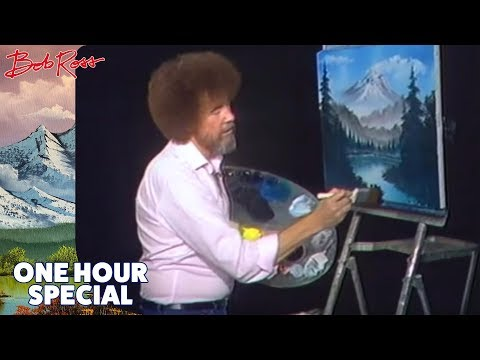

--------------------------------------------------


In [83]:
#Some real life examples of videos with comments enabled and disabled:
videos = [
    {
        'title': 'Disabled cat is so happy to make a friend',
        'video_id': 'y272rQiJeEw',
        'comments_disabled': 'No',
        'R2': 0.9188,
        'MAE': 0.00122
    },
    {
        'title': 'YouTube Disabled Comments on My Videos - YouTube Banned Comments?',
        'video_id': 'bOYl_FjqG_0',
        'comments_disabled': 'Yes',
        'R2': 0.9269,
        'MAE': 0.00110
    },
    {
        'title': 'Bob Ross - One Hour Special - The Grandeur of Summer',
        'video_id': 'mT0RNrTDHkI',
        'comments_disabled': 'No',
        'R2': 0.7622,
        'MAE': 1866625.27
    }
]

# Display videos with R² and MAE
for v in videos:
    print(f"Title: {v['title']}")
    print(f"Comments Disabled: {v['comments_disabled']}")
    print(f"R² Score: {v['R2']}")
    print(f"MAE: {v['MAE']}")
    display(YouTubeVideo(v['video_id'], width=640, height=360))
    print("--------------------------------------------------")


  #These real life examples of videos show the R2 score and the MAE as well and whether the comments were disabled or not for each video. The first video “Disabled cat is so happy to make a friend” had comments enabled. The classification and regression Tree accurately reflect these outcomes, with the regression tree achieving a high R² (0.9188) and very low MAE (0.00122). With the second video, “YouTube Disabled Comments on My Videos - YouTube Banned Comments?” had comments disabled. Both of the CART models correctly captured this, with the regression tree showing strong predictive accuracy (R² = 0.9269, MAE = 0.00110) as well. The video used for MLR, “Bob Ross - One Hour Special - The Grandeur of Summer” had comments enabled. Linear Regression struggles with this video, reflected by a much lower R² (0.7622) and extremely high MAE (~1.87 million), which is because simple linear models fail to capture non-linear relationships in the dataset, so whether the comments should be disabled or not isn't accurately predicted.
